In [44]:
import numpy as np
import matplotlib.pyplot as plt
import imageio
from matplotlib.colors import ListedColormap

In [45]:
def game_theory_sim(b, duration, make_gif=False, gen_random=False):

    SIZE = 201

    Cooperator = np.int8(0)
    Defector = np.int8(1)

    if not gen_random:
        # 1 for cooperator, -1 for defector
        matrix = np.full((SIZE, SIZE), Cooperator)
        # start with one defector in the middle
        matrix[100, 100] = Defector
    else:
        matrix = np.random.randint(0, 2, (SIZE, SIZE))


    strategy = np.array([
        [1,0],
        [b,0]
    ])

    if make_gif:
        frames = []
        colors = ['blue', 'red', 'yellow', 'green']
        cmap = ListedColormap(colors)

    for _ in range(duration):
        right = np.roll(matrix, 1, axis=1)
        left = np.roll(matrix, -1, axis=1)
        up = np.roll(matrix, 1, axis=0)
        down = np.roll(matrix, -1, axis=0)

        up_right = np.roll(right, 1, axis=0)
        up_left = np.roll(left, 1, axis=0)
        down_right = np.roll(right, -1, axis=0)
        down_left = np.roll(left, -1, axis=0)

        score = strategy[matrix, matrix] + strategy[matrix, right] + strategy[matrix, left] + strategy[matrix, up] + strategy[matrix, down] + strategy[matrix, up_left] + strategy[matrix, up_right] + strategy[matrix, down_left] + strategy[matrix, down_right]
        
        score_right = np.roll(score, 1, axis=1)
        score_left = np.roll(score, -1, axis=1)
        score_up = np.roll(score, 1, axis=0)
        score_down = np.roll(score, -1, axis=0)
        score_up_right = np.roll(score_right, 1, axis=0)
        score_up_left = np.roll(score_left, 1, axis=0)
        score_down_right = np.roll(score_right, -1, axis=0)
        score_down_left = np.roll(score_left, -1, axis=0)

        all_scores = np.stack([
            score,
            score_right,
            score_left,
            score_up,
            score_down,
            score_up_left,
            score_up_right,
            score_down_left,
            score_down_right
        ])

        strategy_neighbors = np.stack([
            matrix,
            right,
            left,
            up,
            down,
            up_left,
            up_right,
            down_left,
            down_right
        ])

        best_score_id = np.argmax(all_scores, axis=0) 
        # axis = 0 because all scores is (9, size, size)

        old_matrix = matrix
        matrix = np.take_along_axis(
            strategy_neighbors,
            best_score_id[np.newaxis,:,:],
            axis=0
        )[0]

        if make_gif:
            visual_matrix = np.zeros((SIZE, SIZE), dtype=int)
            visual_matrix[(old_matrix == 0) & (matrix == 0)] = 0 # C->C
            visual_matrix[(old_matrix == 0) & (matrix == 1)] = 1 # D->C
            visual_matrix[(old_matrix == 1) & (matrix == 0)] = 2 # C->D
            visual_matrix[(old_matrix == 1) & (matrix == 1)] = 3 # D->D

            frame_img = (cmap(visual_matrix / 3.0)[:, :, :3] * 255).astype(np.uint8)
            frames.append(frame_img)

    if make_gif:
        if gen_random:
            imageio.mimsave(f'game_theory_random_{b}.gif', frames, fps=10, loop=0)
        else:
            imageio.mimsave(f'game_theory_{b}.gif', frames, fps=10, loop=0)
        print("gif saved!")

    return np.sum(matrix) / SIZE**2 

print(game_theory_sim(1.9, 150, True))
print(game_theory_sim(2.08, 150, True))

gif saved!
0.71505655800599
gif saved!
0.04309299274770426


b = 1.0
gif saved!
b = 1.031
b = 1.061
b = 1.092
b = 1.122
b = 1.153
gif saved!
b = 1.184
b = 1.214
b = 1.245
b = 1.276
b = 1.306
gif saved!
b = 1.337
b = 1.367
b = 1.398
b = 1.429
b = 1.459
gif saved!
b = 1.49
b = 1.52
b = 1.551
b = 1.582
b = 1.612
gif saved!
b = 1.643
b = 1.673
b = 1.704
b = 1.735
b = 1.765
gif saved!
b = 1.796
b = 1.827
b = 1.857
b = 1.888
b = 1.918
gif saved!
b = 1.949
b = 1.98
b = 2.01
b = 2.041
b = 2.071
gif saved!
b = 2.102
b = 2.133
b = 2.163
b = 2.194
b = 2.224
gif saved!
b = 2.255
b = 2.286
b = 2.316
b = 2.347
b = 2.378
gif saved!
b = 2.408
b = 2.439
b = 2.469
b = 2.5
(50, 2)


Text(0, 0.5, 'f')

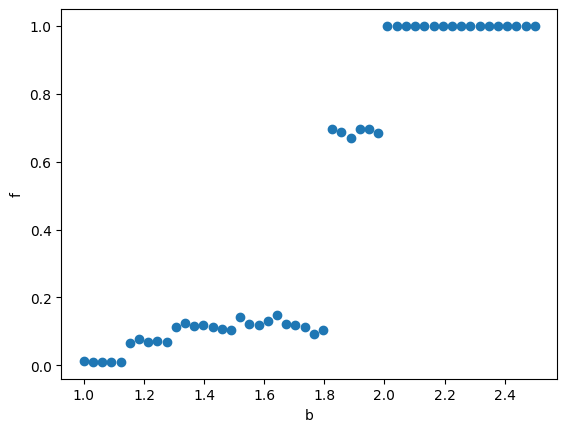

In [46]:
start = 1.0
stop = 2.5
count = 50
duration_per_run = 500
b_values = np.linspace(start, stop, count)

results = []
i = 0
for b in b_values:
    
    print(f"b = {round(b, 3)}")
    make_gif = False
    if i % 5 == 0:
        make_gif=True
        
    f = game_theory_sim(b, duration_per_run, make_gif=make_gif, gen_random=True)
    # print(f"-> f = {f}")
    results.append((b,f))
    i += 1

results = np.array(results)
print(results.shape)

plt.scatter(results[:,0], results[:,1])
plt.xlabel("b")
plt.ylabel("f")